In [79]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

In [80]:
card_transdata = pd.read_csv("card_transdata (1).csv")
card_transdata.head()

,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
0,57.877857,0.311140,1.945940,1.0,1.0,0.0,0.0,0
1,10.829943,0.175592,1.294219,1.0,NaN,0.0,0.0,0
2,5.091079,NaN,0.427715,1.0,0.0,0.0,1.0,0
3,2.247564,5.600044,0.362663,1.0,1.0,0.0,1.0,0
4,44.190936,0.566486,2.222767,1.0,1.0,0.0,1.0,0


In [81]:
card_transdata.shape

(999, 8)

In [82]:
card_transdata.info()

<class 'pandas.DataFrame'>
RangeIndex: 999 entries, 0 to 998
Data columns (total 8 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   distance_from_home              999 non-null    float64
 1   distance_from_last_transaction  996 non-null    float64
 2   ratio_to_median_purchase_price  997 non-null    float64
 3   repeat_retailer                 992 non-null    float64
 4   used_chip                       995 non-null    float64
 5   used_pin_number                 997 non-null    float64
 6   online_order                    995 non-null    float64
 7   fraud                           999 non-null    int64  
dtypes: float64(7), int64(1)
memory usage: 62.6 KB


In [83]:
card_transdata.describe()

,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
count,999.000000,996.000000,997.000000,992.000000,995.000000,997.000000,995.000000,999.000000
mean,26.876607,5.437319,1.655069,0.892137,0.313568,0.117352,0.673367,0.079079
std,63.899697,35.668094,2.351386,0.310364,0.464176,0.322001,0.469218,0.269997
min,0.104184,0.001448,0.016933,0.000000,0.000000,0.000000,0.000000,0.000000
25%,3.990543,0.306441,0.468123,1.000000,0.000000,0.000000,0.000000,0.000000
50%,10.340321,0.958539,0.955504,1.000000,0.000000,0.000000,1.000000,0.000000
75%,25.393952,3.137259,1.922025,1.000000,1.000000,0.000000,1.000000,0.000000
max,965.910612,990.070315,36.074366,1.000000,1.000000,1.000000,1.000000,1.000000


Data Wrangling

In [84]:
card_transdata.isnull().sum()

distance_from_home                0
distance_from_last_transaction    3
ratio_to_median_purchase_price    2
repeat_retailer                   7
used_chip                         4
used_pin_number                   2
online_order                      4
fraud                             0
dtype: int64

In [85]:
card_transdata_clean = card_transdata.dropna()
print(card_transdata_clean.shape)

(977, 8)


In [86]:
card_transdata_clean.head()

,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
0,57.877857,0.311140,1.945940,1.0,1.0,0.0,0.0,0
3,2.247564,5.600044,0.362663,1.0,1.0,0.0,1.0,0
4,44.190936,0.566486,2.222767,1.0,1.0,0.0,1.0,0
5,5.586408,13.261073,0.064768,1.0,0.0,0.0,0.0,0
6,3.724019,0.956838,0.278465,1.0,0.0,0.0,1.0,0


Visualize the Data

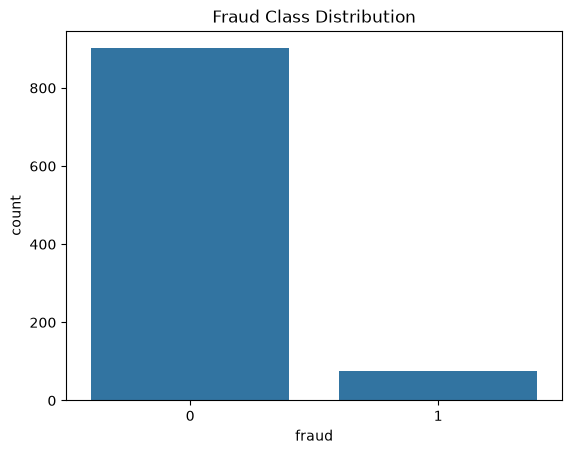

In [87]:
sns.countplot(data=card_transdata_clean, x="fraud")
plt.title("Fraud Class Distribution")
plt.show()

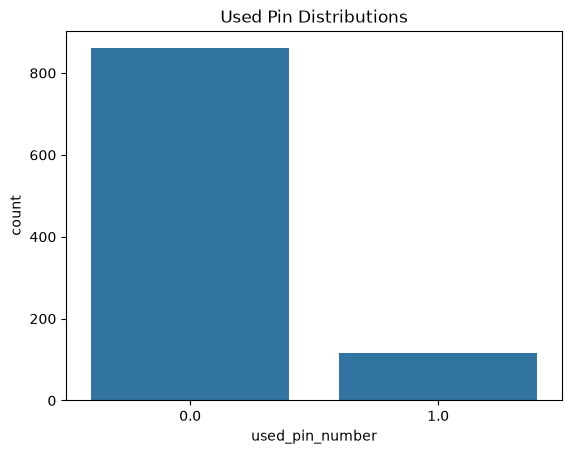

In [88]:
sns.countplot(data=card_transdata_clean, x="used_pin_number")
plt.title("Used Pin Distributions")
plt.show()

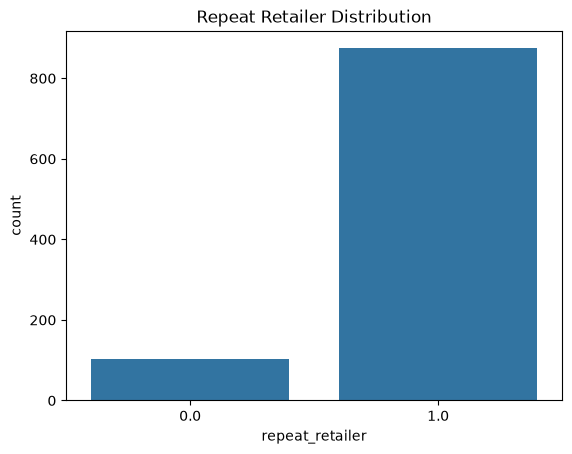

In [89]:
sns.countplot(data=card_transdata_clean, x="repeat_retailer")
plt.title("Repeat Retailer Distribution")
plt.show()

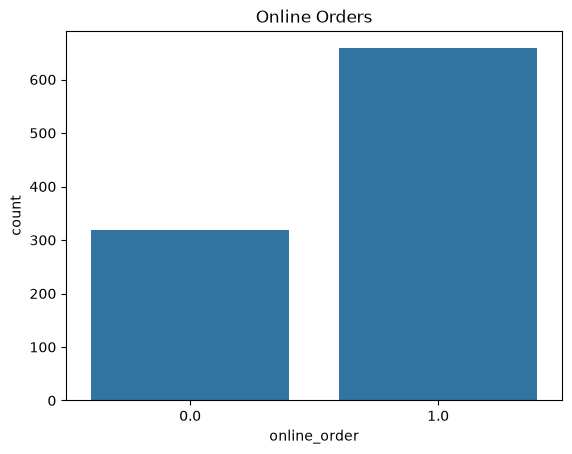

In [90]:
sns.countplot(data=card_transdata_clean, x="online_order")
plt.title("Online Orders")
plt.show()

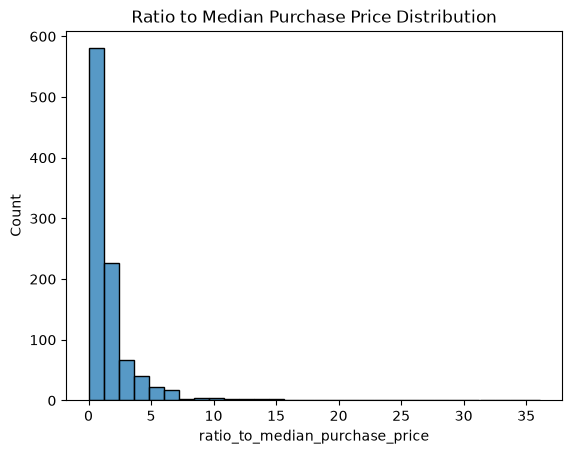

In [91]:
sns.histplot(data=card_transdata_clean, x="ratio_to_median_purchase_price", bins=30)
plt.title("Ratio to Median Purchase Price Distribution")
plt.show()

Better Visualizations: Bivariate Visualizations

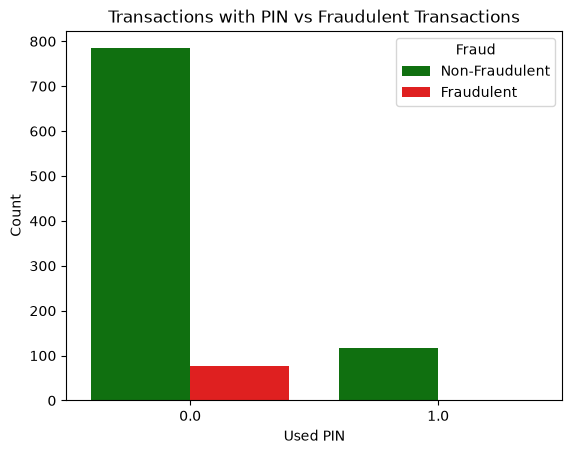

In [92]:
ax = sns.countplot(data=card_transdata_clean, x="used_pin_number", hue="fraud", palette=["green", "red"])
ax.set_title("Transactions with PIN vs Fraudulent Transactions")
ax.set_xlabel("Used PIN")
ax.set_ylabel("Count")
handles, _ = ax.get_legend_handles_labels()
ax.legend(handles, ["Non-Fraudulent", "Fraudulent"], title="Fraud")
plt.show()

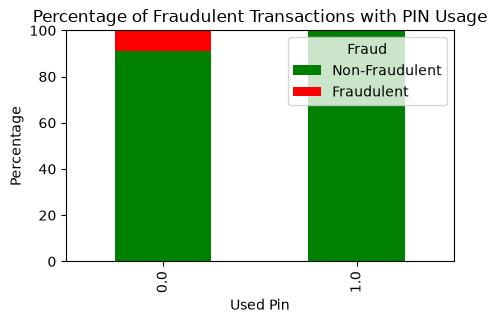

In [93]:
fraud_percentage_by_pin = (
    card_transdata_clean.groupby("used_pin_number")["fraud"]
    .value_counts(normalize=True)
    .unstack()
    .mul(100)
)
ax = fraud_percentage_by_pin.plot(
    kind="bar", stacked=True, figsize=(5, 3), color=["green", "red"]
)
ax.set_title("Percentage of Fraudulent Transactions with PIN Usage")
ax.set_xlabel("Used Pin")
ax.set_ylabel("Percentage")
handles, _ = ax.get_legend_handles_labels()
ax.legend(handles, ["Non-Fraudulent", "Fraudulent"], title="Fraud")
plt.show()

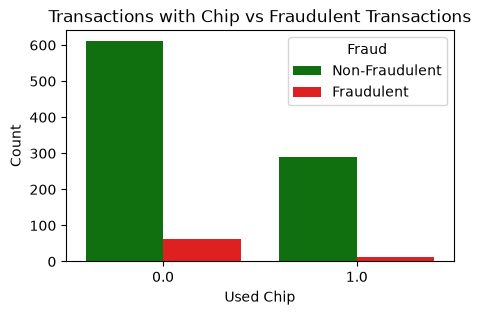

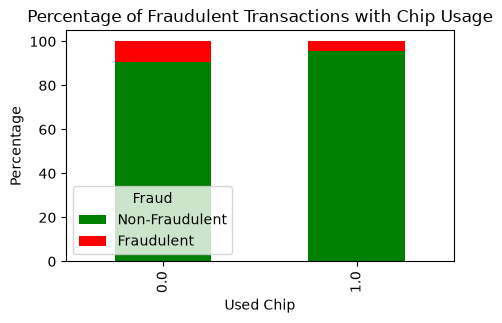

In [94]:
plt.figure(figsize=(5, 3))
sns.countplot(
    data=card_transdata_clean,
    x="used_chip",
    hue="fraud",
    palette=["green", "red"],
)
plt.title("Transactions with Chip vs Fraudulent Transactions")
plt.xlabel("Used Chip")
plt.ylabel("Count")
handles, _ = plt.gca().get_legend_handles_labels()
plt.legend(handles, ["Non-Fraudulent", "Fraudulent"], title="Fraud")
plt.show()

fraud_percentage_by_chip = (
    card_transdata_clean.groupby("used_chip")["fraud"]
    .value_counts(normalize=True)
    .unstack()
    .mul(100)
)
ax = fraud_percentage_by_chip.plot(
    kind="bar", stacked=True, color=["green", "red"], figsize=(5, 3)
)
ax.set_title("Percentage of Fraudulent Transactions with Chip Usage")
ax.set_xlabel("Used Chip")
ax.set_ylabel("Percentage")
handles, _ = ax.get_legend_handles_labels()
ax.legend(handles, ["Non-Fraudulent", "Fraudulent"], title="Fraud")
plt.show()

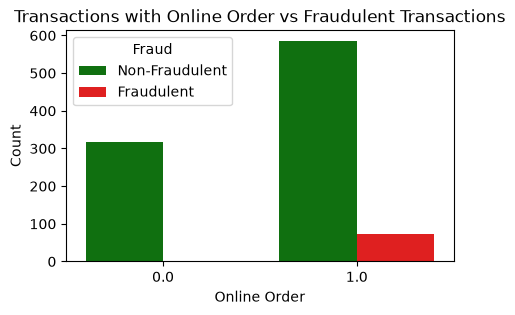

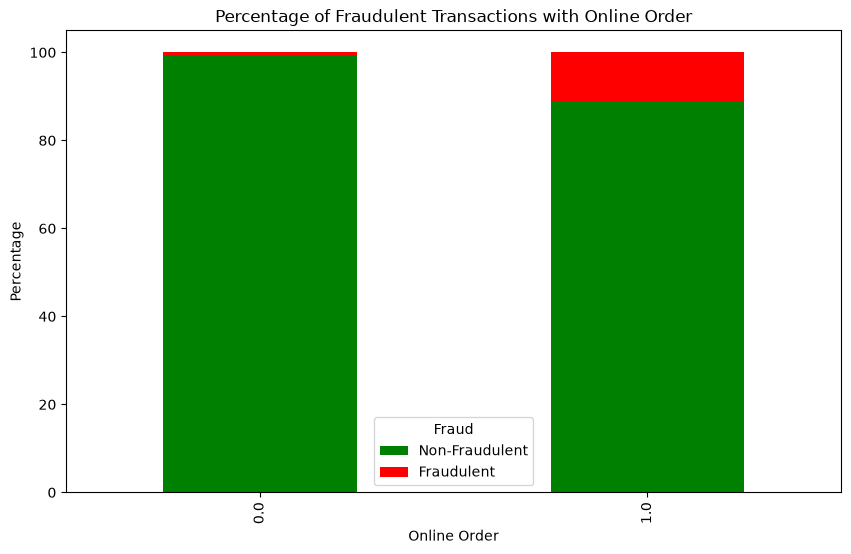

In [95]:
plt.figure(figsize=(5, 3))
sns.countplot(
    data=card_transdata_clean,
    x="online_order",
    hue="fraud",
    palette=["green", "red"],
)
plt.title("Transactions with Online Order vs Fraudulent Transactions")
plt.xlabel("Online Order")
plt.ylabel("Count")
handles, _ = plt.gca().get_legend_handles_labels()
plt.legend(handles, ["Non-Fraudulent", "Fraudulent"], title="Fraud")
plt.show()

fraud_percentage_by_online_order = (
    card_transdata_clean.groupby("online_order")["fraud"]
    .value_counts(normalize=True)
    .unstack()
    .mul(100)
)
ax = fraud_percentage_by_online_order.plot(
    kind="bar", stacked=True, color=["green", "red"], figsize=(10, 6)
)
ax.set_title("Percentage of Fraudulent Transactions with Online Order")
ax.set_xlabel("Online Order")
ax.set_ylabel("Percentage")
handles, _ = ax.get_legend_handles_labels()
ax.legend(handles, ["Non-Fraudulent", "Fraudulent"], title="Fraud")
plt.show()

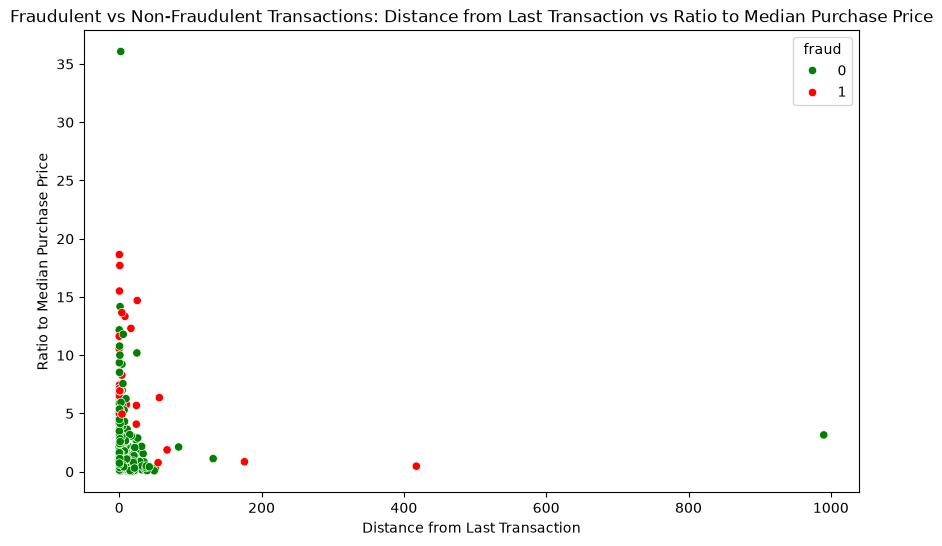

In [96]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=card_transdata_clean,
    x="distance_from_last_transaction",
    y="ratio_to_median_purchase_price",
    hue="fraud",
    palette={0: "green", 1: "red"},
)
plt.title("Fraudulent vs Non-Fraudulent Transactions: Distance from Last Transaction vs Ratio to Median Purchase Price")
plt.xlabel("Distance from Last Transaction")
plt.ylabel("Ratio to Median Purchase Price")
plt.show()